
# Toronto Blue Jays Roster Analysis (2025 vs. 2026)

## 1. Introduction & Research Objectives

### Background

The Toronto Blue Jays declined from 94 wins in 2025 to 79 wins in 2026, despite improvements in overall run prevention and advanced defensive metrics.

Previous analyses identified a substantial decline in offensive production, particularly among returning hitters, alongside changes in pitching personnel.

This notebook examines roster continuity and turnover between the two seasons to better understand how changes in player personnel relate to Toronto's overall performance.

### Research Questions

1. How many players returned from the 2025 roster in 2026?
2. How much roster turnover occurred between the two seasons?
3. How did participation differ among returning and season-specific players?
4. How do roster changes relate to the offensive and pitching findings?

### Analytical Approach

Using cleaned team roster datasets, players will be classified as returning, 2025-only, or 2026-only based on their recorded appearances.

Roster composition and participation will be compared using pandas and matplotlib, with findings connected to previously completed player-level analyses.

These comparisons describe roster changes and associations with team performance rather than establishing causal explanations.


In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned roster datasets
roster_2025 = pd.read_csv("../data/processed/roster_2025_clean.csv")
roster_2026 = pd.read_csv("../data/processed/roster_2026_clean.csv")

# Display roster dimensions
print("2025 Roster:", roster_2025.shape)
print("2026 Roster:", roster_2026.shape)

# Preview the datasets
display(roster_2025.head())
display(roster_2026.head())


2025 Roster: (58, 2)
2026 Roster: (64, 2)


,Player,G
0,Addison Barger,135
1,Jacob Barnes,6
2,Chris Bassitt,32
3,José Berríos,31
4,Bo Bichette,139


,Player,G
0,Tanner Andrews,2
1,Spencer Arrighetti,7
2,Addison Barger,9
3,Brett Bateman,41
4,Shane Bieber,11



## 2. Roster Continuity and Turnover

This section examines changes in Toronto's roster composition between the 2025 and 2026 seasons.

Players are classified into three groups:

- **Returning players:** Appeared in both seasons.
- **2025-only players:** Appeared in 2025 but not in 2026.
- **2026-only players:** Appeared in 2026 but not in 2025.

These classifications measure roster continuity and turnover based on season appearances, rather than official transaction records.


In [2]:

# Convert player names into sets
players_2025 = set(roster_2025["Player"])
players_2026 = set(roster_2026["Player"])

# Identify players who appeared in both seasons
returning_players = players_2025 & players_2026

# Identify players who appeared in only one season
only_2025 = players_2025 - players_2026
only_2026 = players_2026 - players_2025

# Display the number of players in each group
print("Returning Players:", len(returning_players))
print("2025-Only Players:", len(only_2025))
print("2026-Only Players:", len(only_2026))


Returning Players: 25
2025-Only Players: 33
2026-Only Players: 39



### Roster Turnover Findings

Toronto experienced substantial roster turnover between the 2025 and 2026 seasons.

Of the 58 players who appeared in 2025, only 25 (43.1%) also appeared in 2026. The remaining 33 players (56.9%) did not return.

Meanwhile, 39 of the 64 players who appeared in 2026 (60.9%) had not appeared for Toronto during the previous season.

These results indicate significant changes in roster composition. However, roster counts alone do not measure the importance of individual players or their contributions to team performance.

Further analysis of player participation is necessary to distinguish changes involving regular contributors from those involving players with limited appearances.



## 3. Player Participation

Roster turnover counts each player equally, regardless of their level of participation.

To provide additional context, this section examines the number of games recorded by returning and season-specific players.

Games played are used as a descriptive measure of participation rather than a direct measure of player value or production. Differences between pitchers and position players must also be considered when interpreting these results.


In [3]:

# Assign roster classifications to each season
roster_2025["Group"] = roster_2025["Player"].apply(
    lambda player: "Returning" if player in returning_players else "2025-Only"
)

roster_2026["Group"] = roster_2026["Player"].apply(
    lambda player: "Returning" if player in returning_players else "2026-Only"
)

# Calculate participation statistics for each roster group
participation_2025 = roster_2025.groupby("Group")["G"].agg(
    ["count", "mean", "median", "max"]
)

participation_2026 = roster_2026.groupby("Group")["G"].agg(
    ["count", "mean", "median", "max"]
)

print("2025 Player Participation:")
display(participation_2025.round(1))

print("2026 Player Participation:")
display(participation_2026.round(1))


2025 Player Participation:


,count,mean,median,max
Group,,,,
2025-Only,33,20.4,13.0,139
Returning,25,72.3,66.0,157


2026 Player Participation:


,count,mean,median,max
Group,,,,
2026-Only,39,24.1,8.0,156
Returning,25,63.4,51.0,158



### Player Participation Findings

Returning players generally recorded more appearances than season-specific players in both seasons.

In 2025, returning players recorded a median of 66 games, compared with 13 games among 2025-only players. In 2026, returning players recorded a median of 51 games, compared with 8 games among 2026-only players.

The returning group's average appearances decreased from 72.3 to 63.4, suggesting reduced overall participation among players present in both seasons.

These findings indicate that much of Toronto's roster turnover involved players with limited appearances, while a substantial group of regular contributors remained.

However, some season-specific players recorded more than 130 games, demonstrating that roster changes also affected highly active contributors.

Because pitching appearances and position-player games are not directly comparable measures of workload, these findings describe roster participation rather than player value.


In [4]:

# Identify the 10 most active 2025-only players
top_2025_only = (
    roster_2025[roster_2025["Group"] == "2025-Only"]
    .sort_values("G", ascending=False)
    .head(10)
)

# Identify the 10 most active 2026-only players
top_2026_only = (
    roster_2026[roster_2026["Group"] == "2026-Only"]
    .sort_values("G", ascending=False)
    .head(10)
)

print("Most Active 2025-Only Players:")
display(top_2025_only[["Player", "G"]])

print("Most Active 2026-Only Players:")
display(top_2026_only[["Player", "G"]])


Most Active 2025-Only Players:


,Player,G
4,Bo Bichette,139
42,Anthony Santander,54
20,Chad Green,45
38,Alan Roden,43
31,Joey Loperfido,41
55,Will Wagner,40
15,Ty France,37
2,Chris Bassitt,32
3,José Berríos,31
11,Seranthony Domínguez,24


Most Active 2026-Only Players:


,Player,G
37,Kazuma Okamoto,156
43,Jesús Sánchez,99
56,Brandon Valenzuela,91
42,Tyler Rogers,74
38,Yohendrick Piñango,58
35,Spencer Miles,49
3,Brett Bateman,41
34,Charles McAdoo,36
48,Josh Smith,35
6,Dylan Cease,29



### Notable Season-Specific Players

Roster turnover involved both limited-appearance players and several regularly utilized contributors.

Among 2025-only players, Bo Bichette recorded 139 games, making him the most active player absent from Toronto's 2026 roster. Chris Bassitt (32 games) and José Berríos (31 games) were also notable season-specific pitching contributors.

Among 2026-only players, Kazuma Okamoto recorded 156 games, followed by Jesús Sánchez (99) and Brandon Valenzuela (91). Pitchers such as Tyler Rogers, Spencer Miles, and Dylan Cease also recorded meaningful participation.

These findings demonstrate that roster turnover extended beyond players with limited appearances and included significant changes in Toronto's regularly utilized personnel.

However, participation alone does not measure player performance or establish the impact of individual roster changes. Those questions require the batting and pitching statistics examined in previous notebooks.



## 4. Returning Player Participation

This section examines changes in appearances among players who appeared in both the 2025 and 2026 seasons.

By comparing each returning player's appearances across seasons, the analysis identifies individuals who experienced the largest reductions in participation.

These changes may reflect injuries, changes in roster roles, or other circumstances. Reduced appearances alone do not establish the underlying cause.


In [6]:

# Select returning players from each season
returning_2025 = roster_2025[
    roster_2025["Player"].isin(returning_players)
][["Player", "G"]]

returning_2026 = roster_2026[
    roster_2026["Player"].isin(returning_players)
][["Player", "G"]]

# Merge both seasons using player names
returning_comparison = pd.merge(
    returning_2025,
    returning_2026,
    on="Player",
    suffixes=("_2025", "_2026")
)

# Calculate the change in appearances
returning_comparison["Change"] = (
    returning_comparison["G_2026"] -
    returning_comparison["G_2025"]
)

# Sort by largest decrease in appearances
returning_comparison = returning_comparison.sort_values(
    "Change", ascending=True
)

# Display all returning players
display(returning_comparison.reset_index(drop=True))


,Player,G_2025,G_2026,Change
0,Addison Barger,135,9,-126
1,Yariel Rodríguez,66,10,-56
2,Alejandro Kirk,130,79,-51
3,Brendon Little,79,30,-49
4,Tyler Heineman,64,33,-31
5,Jonatan Clase,34,9,-25
6,Eric Lauer,28,8,-20
7,Jeff Hoffman,71,51,-20
8,George Springer,140,126,-14
9,Davis Schneider,82,69,-13



### Returning Player Participation Findings

Changes in appearances among Toronto's 25 returning players revealed several important personnel developments.

**Reduced Participation**

- Addison Barger experienced the largest decline, falling from 135 games in 2025 to just 9 in 2026 due to multiple injuries.
- Brendon Little (-49 games) and Davis Schneider (-13 games) experienced performance-related assignments to the minor leagues.
- Tyler Heineman, Jeff Hoffman, and Kevin Gausman recorded fewer appearances partly because of midseason trades.
- Other significant declines, including those of Yariel Rodríguez and Alejandro Kirk, require additional context before attributing them to specific causes.

**Increased Participation**

- Trey Yesavage increased from 3 to 20 appearances after making his MLB debut late in September 2025.
- Louis Varland increased from 23 to 71 appearances after joining Toronto midway through the 2025 season.
- Andrés Giménez (+47 games) and Daulton Varsho (+28 games) also recorded substantial increases in appearances.

### Interpretation

These findings demonstrate that roster participation changed for several distinct reasons, including injuries, performance-related assignments, midseason transactions, and expanded roles.

The substantial loss of appearances from certain returning players, particularly Addison Barger, provides important context for Toronto's reduced offensive production.

However, changes in appearances do not directly measure the impact of individual players on team performance. The offensive and pitching analyses provide stronger evidence of how production changed between seasons.


### Case Study: Alejandro Kirk and Brandon Valenzuela

Alejandro Kirk's fractured thumb in April 2026 created an unexpected opportunity for rookie catcher Brandon Valenzuela.

Kirk's appearances declined from 130 games in 2025 to 79 in 2026, while Valenzuela made his MLB debut on April 5 and eventually appeared in 91 games.

Valenzuela emerged as a productive contributor during Kirk's absence and retained a major-league role following Kirk's return.

This example demonstrates how injuries can reshape roster composition and create opportunities for emerging players.

Although Toronto lost significant playing time from an established catcher, Valenzuela's emergence helped provide additional depth at the position.

The case highlights why changes in player availability should be evaluated alongside the contributions of replacement players rather than treating every absence as an equivalent loss of production.



### Visualization: Changes in Returning Player Participation

To illustrate changes in roster participation, the five largest decreases and five largest increases in appearances among returning players are compared.

This visualization highlights changes in player availability and utilization between the two seasons.

Changes in appearances should not be interpreted as direct measures of performance, particularly because pitchers and position players have different playing schedules.


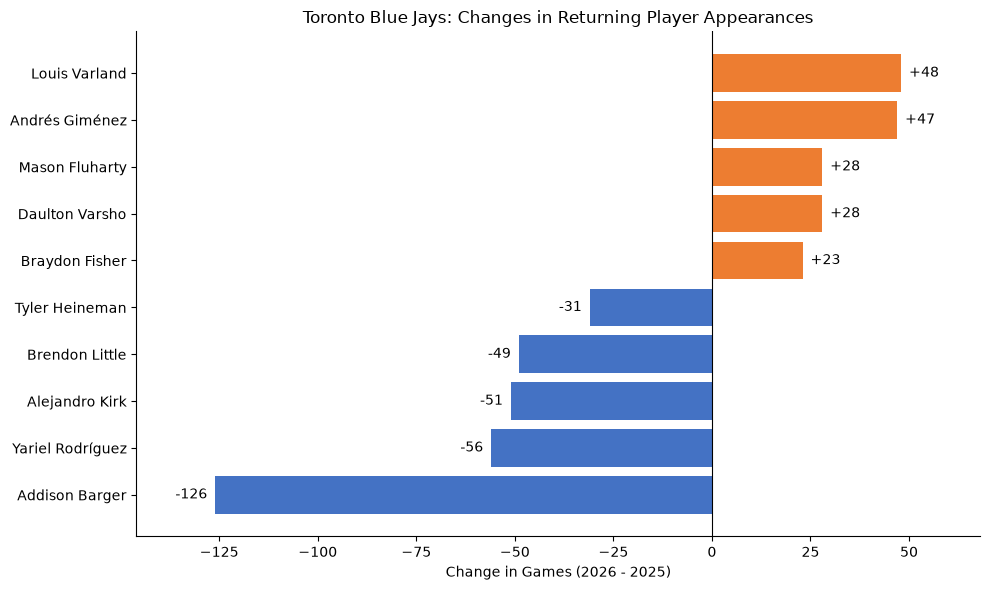

In [7]:

# Select the five largest decreases and increases
largest_decreases = returning_comparison.nsmallest(5, "Change")
largest_increases = returning_comparison.nlargest(5, "Change")

# Combine the selected players
participation_changes = pd.concat([
    largest_decreases,
    largest_increases
])

# Sort players by change in appearances
participation_changes = participation_changes.sort_values("Change")

# Assign colors based on increase or decrease
colors = [
    "#4472C4" if change < 0 else "#ED7D31"
    for change in participation_changes["Change"]
]

# Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    participation_changes["Player"],
    participation_changes["Change"],
    color=colors
)

# Add a zero reference line
ax.axvline(0, color="black", linewidth=0.8)

# Add values beside each bar
for i, change in enumerate(participation_changes["Change"]):
    ax.text(
        change + (2 if change > 0 else -2),
        i,
        f"{change:+d}",
        va="center",
        ha="left" if change > 0 else "right"
    )

# Format the chart
ax.set_title("Toronto Blue Jays: Changes in Returning Player Appearances")
ax.set_xlabel("Change in Games (2026 - 2025)")
ax.set_xlim(
    participation_changes["Change"].min() - 20,
    participation_changes["Change"].max() + 20
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



### Visualization: Roster Departures and Additions

This visualization compares the ten most active players who appeared exclusively in either the 2025 or 2026 Toronto Blue Jays season.

The 2025-only group represents players who did not appear for Toronto in 2026, while the 2026-only group represents players who did not appear for Toronto in 2025.

Games recorded are used to highlight notable changes in roster participation rather than measure player value or performance. These classifications do not necessarily indicate formal departures or new acquisitions.


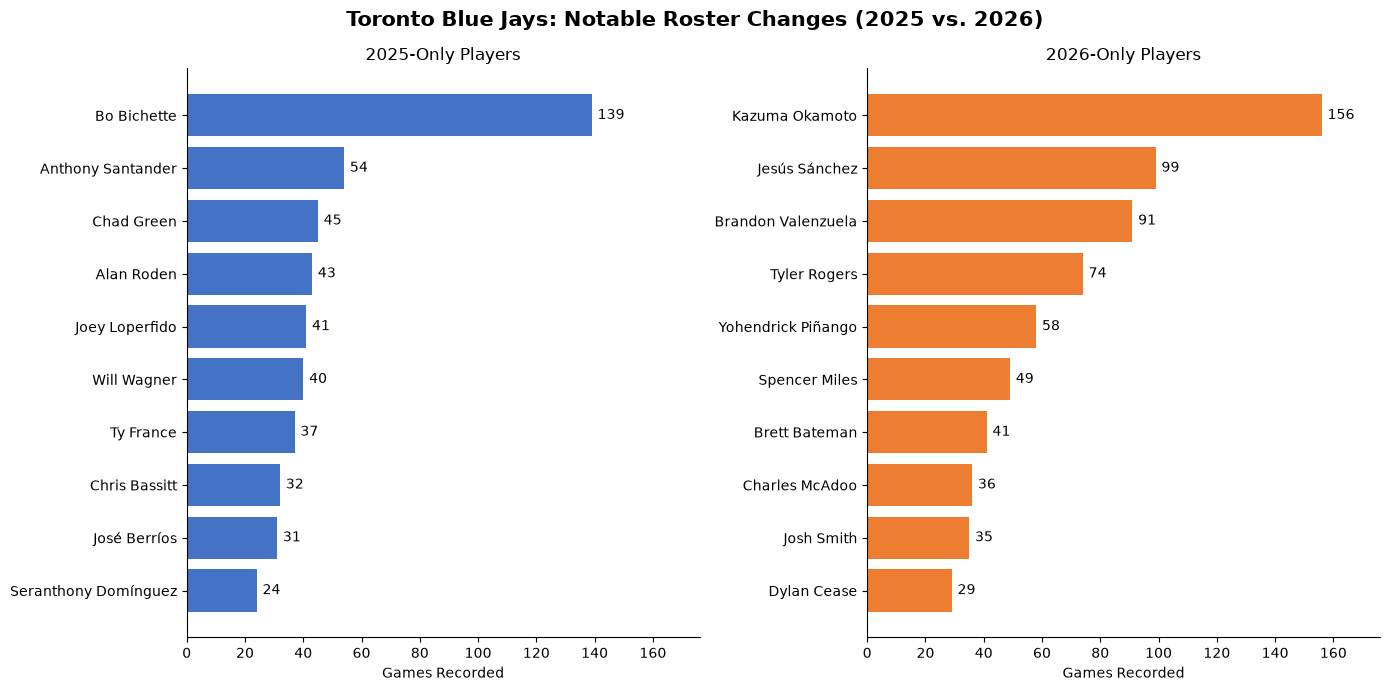

In [8]:

# Sort players from fewest to most games for horizontal plotting
plot_2025 = top_2025_only.sort_values("G")
plot_2026 = top_2026_only.sort_values("G")

# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# 2025-only players
axes[0].barh(
    plot_2025["Player"],
    plot_2025["G"],
    color="#4472C4"
)

axes[0].set_title("2025-Only Players")
axes[0].set_xlabel("Games Recorded")

# 2026-only players
axes[1].barh(
    plot_2026["Player"],
    plot_2026["G"],
    color="#ED7D31"
)

axes[1].set_title("2026-Only Players")
axes[1].set_xlabel("Games Recorded")

# Use a consistent horizontal scale
max_games = max(plot_2025["G"].max(), plot_2026["G"].max())

for ax in axes:
    ax.set_xlim(0, max_games + 20)

    # Add game totals beside each bar
    for bar in ax.patches:
        ax.text(
            bar.get_width() + 2,
            bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width())}",
            va="center"
        )

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Add an overall title
fig.suptitle(
    "Toronto Blue Jays: Notable Roster Changes (2025 vs. 2026)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## 5. Final Roster Analysis Conclusion

The Toronto Blue Jays experienced substantial roster turnover between the 2025 and 2026 seasons, alongside important changes in player availability and individual contributions.

### Roster Continuity and Turnover

Of the 58 players who appeared for Toronto in 2025, only 25 (43.1%) also appeared in 2026. Meanwhile, 39 of the 64 players who appeared in 2026 (60.9%) had not appeared for Toronto during the previous season.

Much of this turnover involved players with limited appearances. However, the absence of established contributors such as Bo Bichette, Chris Bassitt, and José Berríos demonstrated that roster changes also affected regularly utilized personnel.

### Returning Player Availability

Returning players generally recorded fewer appearances in 2026, with their median declining from 66 to 51 games.

Several notable players experienced substantial reductions in participation:

- Addison Barger declined from 135 to 9 games due to injuries.
- Alejandro Kirk declined from 130 to 79 games following a fractured thumb.
- Brendon Little and Davis Schneider experienced performance-related assignments to the minor leagues.

Other changes reflected increased opportunities. Trey Yesavage and Louis Varland recorded more appearances following their limited time with Toronto in 2025, while Brandon Valenzuela made his MLB debut in 2026 and assumed a larger role following Kirk's injury.

These findings demonstrate that changes in participation reflected multiple circumstances, including injuries, roster transactions, performance-related decisions, and expanded roles.

### Connection to Offensive and Pitching Performance

The roster findings provide additional context for the statistical patterns identified in the previous notebooks.

**Offensive Performance**

Toronto scored 150 fewer runs in 2026. Previous analysis revealed declining OPS among eight of nine qualified returning hitters, while roster changes and injuries reduced the availability of several established offensive contributors.

Although 2026-only hitters collectively provided more production than the 2025-only group, these contributions were insufficient to offset the broader decline among returning hitters.

**Pitching Performance**

Despite deterioration among several returning pitchers, Toronto's overall run prevention improved.

The 2026-only pitching group recorded a collective ERA of 3.64, compared with 4.68 among 2025-only pitchers. This suggests that changes in pitching personnel helped offset weaker performances among returning pitchers.

### Overall Conclusion

The roster analysis demonstrates that Toronto's decline cannot be attributed to roster turnover alone.

Rather, the evidence highlights a combination of reduced availability among established contributors, declining offensive production among returning hitters, and changes in personnel utilization.

Newcomers and expanded player roles helped offset some of these losses, particularly within the pitching staff, but were insufficient to overcome the team's substantial offensive decline.

Combined with the previous analyses, these findings strengthen the conclusion that **declining offensive production was the primary statistical contributor to Toronto's worsening run differential**, while pitching and advanced defensive improvements partially offset that decline.

Although roster changes provide important context, their independent causal effects cannot be established from the available descriptive statistics.
